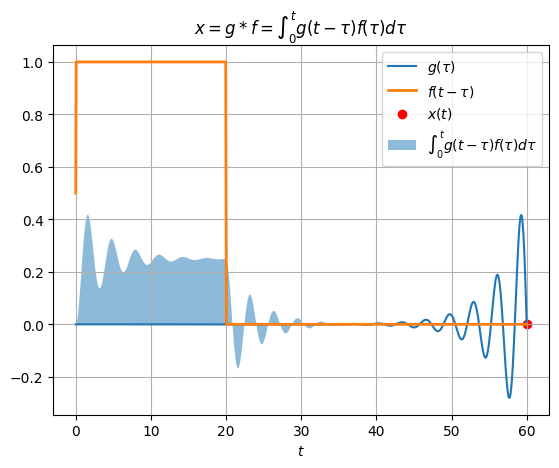

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# Define symbolic variables
t, s = sp.symbols('t s')

# System parameters
m = 1
b = 0.5
k = 4

denG = m * s**2 + b * s + k
G = 1 / denG

# Inverse Laplace transform
gsym = sp.inverse_laplace_transform(G, s, t) * sp.Heaviside(t)
fsym = sp.Heaviside(t) - sp.Heaviside(t - 20)

# Convert symbolic expressions to Python functions
g = sp.lambdify(t, gsym, 'numpy')
f = sp.lambdify(t, fsym, 'numpy')

# Time settings
dt = 0.05
tt = np.arange(0, 60 + dt, dt)
tau = tt
nn = len(tt)

# Initialize results arrays
convol = np.zeros(nn)

# Create figure for animation
fig, ax = plt.subplots()
line1, = ax.plot([], [], label=r"$g(\tau)$")
line2, = ax.plot([], [], linewidth=2, linestyle="-", label=r"$f(t-\tau)$")
scatter = ax.scatter([], [], color='red', label=r"$x(t)$")
fill_between = ax.fill_between([], [], alpha=0.5, label=r"$\int_0^t g(t-\tau)f(\tau) d\tau$")

ax.set_xlabel(r'$t$')
ax.set_title(r'$x = g * f = \int_0^t g(t-\tau)f(\tau)d\tau$')
ax.grid(True)
ax.legend(loc="upper right")

# Animation update function
def update(k):
    ax.clear()
    gg = g(tt[k] - tau)
    ff = f(tau)
    convol[k] = np.trapz(gg * ff, tau)

    ax.plot(tt, gg, label=r"$g(\tau)$")
    ax.plot(tt, ff, linewidth=2, linestyle="-", label=r"$f(t-\tau)$")
    ax.scatter(tt[k], convol[k], color='red', label=r"$x(t)$")
    ax.fill_between(tt[:k+1], convol[:k+1], alpha=0.5, label=r"$\int_0^t g(t-\tau)f(\tau) d\tau$")

    ax.set_xlabel(r'$t$')
    ax.set_title(r'$x = g * f = \int_0^t g(t-\tau)f(\tau)d\tau$')
    ax.grid(True)
    ax.legend(loc="upper right")

# Create animation
ani = FuncAnimation(fig, update, frames=nn, repeat=False)

# Save animation as a GIF using Pillow
ani.save("convolution_animation.gif", writer=PillowWriter(fps=20))

plt.show()
